## Problem Statement
    
### Earthquake
    
    The earth is made of 4 layers inner core, outer core, mantle and crust. The top most is the crust, however this crust and top part of mantle are not completely one sheet warpping the core instead they are more like lego pieces put together. Consequently, these pieces are always at risk of falling apart. In reality, these pieces move around sometimes sliding and bumping into each other. If you've had a geography class back in high school, you must be familiar with the term tectonic plates, they are nothing but the lego pieces we've been talking about. When these plates(pieces) bump into each other they might slip out of place causing imbalance in the surface which is considered an earthquake. This explanation is only an overview of what and how an earthquake takes place, if you're interested check this link out:

https://www.usgs.gov/natural-hazards/earthquake-hazards/science/science-earthquakes?qt-science_center_objects=0#qt-science_center_objects
    
    

### Importance of Forecasting earthquakes
    
    Forecasting earthquakes is one of the most important problems in Earth science. The ability to forecast would help the respective organizations to be better prepared for any of these natural phenomenon. With a good amount of confidence that some disaster could occur, people can be advised beforehand to take proper measures to ensure minimal loss to life and property. It is fairly safe to say(based on history) that these events could be forecasted with probability concepts. In that spirit, we shall use some probability concepts to do our best in forecasting a potential risk of earthquake.
    

### The problem
    
    On a high level, the aim is to identify when an earthquake would take place. At a deeper level, understanding a problem would require knowledge of the premise, what factors might contribute to premise, and the expectation from solution. We know the idea is to forecast a future occurance of earthquake but what factors are we going to use would be clear once we look at the data.

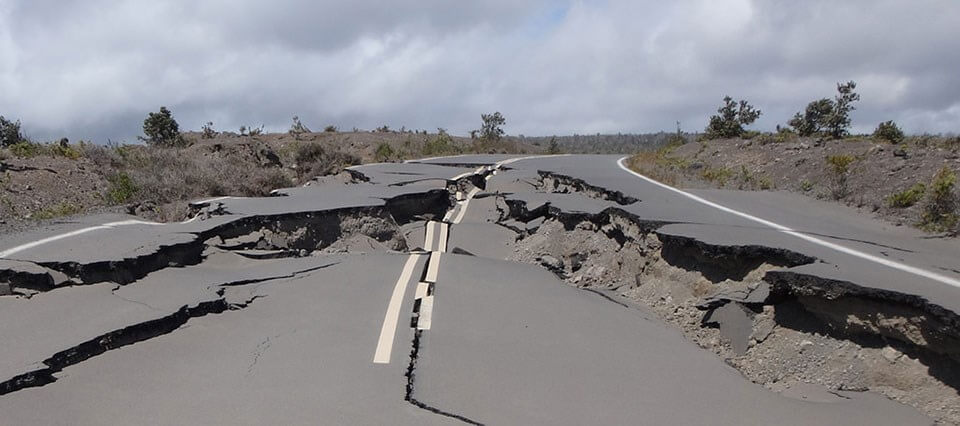

In [1]:
from IPython.display import Image
Image("earthquake.png")


### Importing Dependencies

In [3]:
import glob
import sys
import os
import warnings
warnings.filterwarnings('ignore')
from tqdm import tqdm

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib.patches as patch
import seaborn as sns

import random
import eli5
import shap  # package used to calculate Shap values
import time


from sklearn.model_selection import StratifiedKFold, KFold, RepeatedKFold
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy.stats import kurtosis
from scipy.stats import skew
from scipy.stats import norm


from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from eli5.sklearn import PermutationImportance
from sklearn.tree import DecisionTreeRegressor
from catboost import CatBoostRegressor,Pool
from sklearn.svm import NuSVR
from scipy import linalg
from sklearn import tree
from sklearn import svm
import lightgbm as lgb
import xgboost as xgb


import graphviz

Using TensorFlow backend.


### The test directory

In [19]:
len(os.listdir(os.path.join('LANL-Earthquake-data/test')))

2624

    We have 2624 files in the test directory each belonging to one segment. So, the idea is to predict the time_to_failure for all these segments

    From the test directory, we can realize that the data is segmented and the aim is to predict time-to-failure for each segment. The train dataset on the other hand isn't divided into segments, it's provided more like a single continous segment. Consider it a segment or not the goal remains same, but since the test set is segmented we shall do the same to train.
    
    Let's randomly generate segments of 100000 rows each.


### Exploratory Data Analysis(EDA) 

    The directory for this project is full of data. We have a predetrmined split of train and test data inside the "LANL-Earthquake-data" folder. Let's load the train data

In [4]:
train = pd.read_csv('LANL-Earthquake-data/train.csv')
train.head()

,acoustic_data,time_to_failure
0,12,1.4691
1,6,1.4691
2,8,1.4691
3,5,1.4691
4,8,1.4691


    It took quite a while to load the data, aproxmately some 2.5-3min. Let's have a look at the specifics of the file(#datapoints, columns) to realize how huge the source is and then the actual size of data.

In [6]:
print(f'Rows: {train.shape[0]}')
print(f'Columns: {train.shape[1]}')

Rows: 629145480
Columns: 2


In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 629145480 entries, 0 to 629145479
Data columns (total 2 columns):
acoustic_data      int64
time_to_failure    float64
dtypes: float64(1), int64(1)
memory usage: 9.4 GB


    The memory currently being used is 9.4GB, this is a little too much for a local PC. One handy way to get around this trouble is identifying how big any given value in a column would get and then change the type from int64 or float64 to int32 or 16 or even 8.

In [13]:
%%time
print(f'Max_value: ',max(train['acoustic_data']))
print(f'Min_value: ',min(train['acoustic_data']))

Max_value:  5444
Min_value:  -5515
Wall time: 1min 43s


In [14]:
%%time
print(f'Max_value: ',max(train['time_to_failure']))
print(f'Min_value: ',min(train['time_to_failure']))

Max_value:  16.1074
Min_value:  9.550396316600001e-05
Wall time: 2min


    We now have a proof that the range of int64/float64 is too huge for data we have and the simple calculation of max itself took a while, imagine if we have to do some complex calculation. I wouldn't be surprised if it takes several minutes or even hours.
    
    One problem at a time, to address the size issue we shall now reduce the range of int and float to 16 and 32 respectively.

In [16]:
train['acoustic_data'] = train['acoustic_data'].astype('int16')
train['time_to_failure'] = train['time_to_failure'].astype('float32')

In [17]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 629145480 entries, 0 to 629145479
Data columns (total 2 columns):
acoustic_data      int16
time_to_failure    float32
dtypes: float32(1), int16(1)
memory usage: 3.5 GB


    There we have it, we've successfully reduced the memory consumption by almost 6GB.

In [20]:
train.describe()

,acoustic_data,time_to_failure
count,6.291455e+08,6.291455e+08
mean,4.519468e+00,4.477084e-01
std,1.073571e+01,2.612789e+00
min,-5.515000e+03,9.550396e-05
25%,2.000000e+00,2.625997e+00
50%,5.000000e+00,5.349798e+00
75%,7.000000e+00,8.173395e+00
max,5.444000e+03,1.610740e+01


    Like we've seen before the huge size of this data is going to make it a problem for working on whole of the data. For the sake for better processing, quicker results we can start working with 100000 rows

In [21]:
train_org = train.copy(deep=True)

In [22]:
train = train.iloc[:100000,:]

In [23]:
train.shape

(100000, 2)

In [25]:
train.describe()

,acoustic_data,time_to_failure
count,100000.000000,100000.000000
mean,5.015940,1.456352
std,5.680238,0.007503
min,-98.000000,1.443598
25%,3.000000,1.449999
50%,5.000000,1.456399
75%,7.000000,1.462800
max,104.000000,1.469100


Because the size of the database is very large, we shall only look at a part of data for faster processing

In [26]:
train.isna().sum()

acoustic_data      0
time_to_failure    0
dtype: int64

    Acoustic_data simply means the signal on the equipment

In [27]:
train['acoustic_data'].value_counts()

 5     11157
 6     10796
 4     10602
 3      9354
 7      9211
       ...  
 72        1
-56        1
 71        1
 93        1
-81        1
Name: acoustic_data, Length: 158, dtype: int64

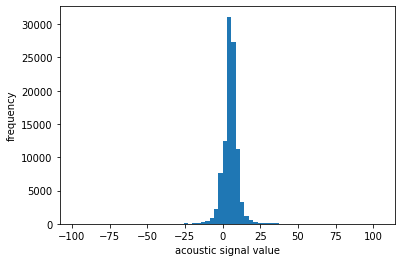

In [31]:
plt.hist(train['acoustic_data'],bins=70)
plt.xlabel('acoustic signal value')
plt.ylabel('frequency')
plt.show()

    Though the signals have occassional high and low values, collection is well centered somewhere around 1-5. We shall anyway confirm this assumption by plotting distribution

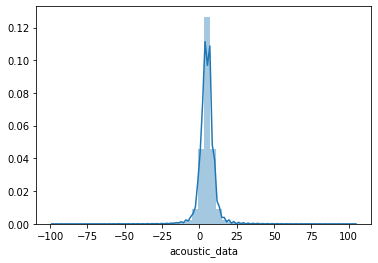

In [40]:
sns.distplot(train["acoustic_data"])
plt.show()

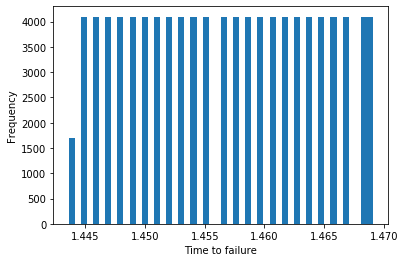

In [33]:
plt.hist(train['time_to_failure'],bins=50)
plt.xlabel('Time to failure')
plt.ylabel('Frequency')
plt.show()

    There's a pretty small range for time_to_failure and hence looking at it by itself doesn't provide us with much of information. Let's look at it in relation to the acoustic signal, we can start off by looking at linear relation if any

Text(0, 0.5, 'Time to failure')

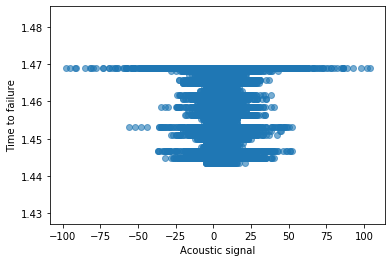

In [35]:
plt.scatter(train['acoustic_data'],train['time_to_failure'],alpha=0.6)
plt.xlabel('Acoustic signal')
plt.ylabel('Time to failure')

    There's no discernable pattern except for the fact that highest time-to-failure occured at broadest of signals. This doesn't necessarily mean that they are linearly related. We can also represent the same relation with a barplot in the spirit of identifying any pattern.

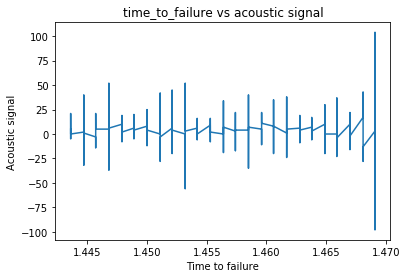

In [37]:
plt.plot(train["time_to_failure"], train["acoustic_data"])
plt.title("time_to_failure vs acoustic signal")
plt.xlabel('Time to failure')
plt.ylabel('Acoustic signal')
plt.show()

    However, we can apply the correlation function to see if there's some relation 

In [38]:
train.corr()

,acoustic_data,time_to_failure
acoustic_data,1.000000,-0.008397
time_to_failure,-0.008397,1.000000


    Like we've suspected and noticed from the charts above, there's close to no linear relationship between the variables

### The benchmark

    We know our target is a numerical feature, so we are going to use regression techniques. However, we can't directly jump into building models. We have, in the beginning decided that predictions are to be done by segment. Let's segment our training data now

In [41]:
rows = 100000
segments = np.floor(train_org.shape[0] / rows)
segments

6291.0

    So, the data is now segmented into 6291 parts, we might want to convert that number to an integer. Now, since the data is segmented, we can't directly use the numbers as is instead will have to use some aggregated metrics to represent respective segments.
    
    As a start we can use mean, median, mode, skew, kurtosis, variance, standard deviation, IQR, sum

In [58]:
segments = int(segments)
X_train = pd.DataFrame(index=range(segments), dtype=np.float64,
                       columns=['mean_', 'median_', 'mode_', 'std', 'var', 'max_', 'min_','sum_','skew_','kurt'])
y_train = pd.DataFrame(index=range(segments), dtype=np.float64,
                       columns=['time_to_failure'])

    Now, the placeholders for train and test data are created. It's time to get to actual calculation of all the aforementioned metrics.
    Before we go ahead, for features we shall use aggregated metrics what about target?
---

    We can still use the average or if the entries are temporal simply the last entry could represent progress till then in any given segment

In [68]:
for segment in tqdm(range(segments)):
    start = segment*rows
    end = (segment*rows)+rows
    data = train_org.iloc[start:end]
    signal = data['acoustic_data'].values
    output = data['time_to_failure'].values[-1]
    
    y_train.loc[segment, 'time_to_failure'] = output
    X_train.loc[segment, 'mean_'] = np.mean(signal)
    X_train.loc[segment, 'median_'] = np.median(signal)
    X_train.loc[segment, 'mode_'] = pd.value_counts(signal).keys()[0]
    X_train.loc[segment, 'std_'] = np.std(signal)
    X_train.loc[segment, 'var_'] = np.var(signal)
    X_train.loc[segment, 'max_'] = np.max(signal)
    X_train.loc[segment, 'min_'] = np.min(signal)
    X_train.loc[segment, 'sum_'] = np.sum(signal)
    X_train.loc[segment, 'skew_'] = skew(signal)
    X_train.loc[segment, 'kurt'] = kurtosis(signal)
    

100%|██████████████████████████████████████████████████████████████████████████████| 6291/6291 [02:10<00:00, 48.07it/s]


In [69]:
X_train.head()

,mean_,median_,mode_,max_,min_,sum_,skew_,kurt,std_,var_
0,5.01594,5.0,5.0,104.0,-98.0,501594.0,-0.071023,32.336677,5.680210,32.264786
1,4.65943,5.0,5.0,181.0,-154.0,465943.0,0.496246,116.642329,5.779182,33.398942
2,4.73945,5.0,5.0,152.0,-150.0,473945.0,0.316915,101.698287,6.199615,38.435224
3,4.81588,5.0,5.0,97.0,-87.0,481588.0,-0.114993,22.802360,5.981707,35.780820
4,4.96553,5.0,5.0,140.0,-106.0,496553.0,0.410932,31.884058,7.515485,56.482522


In [70]:
y_train.head()

,time_to_failure
0,1.443598
1,1.418096
2,1.391499
3,1.365897
4,1.339300


In [71]:
X_train.isna().sum()

mean_      0
median_    0
mode_      0
max_       0
min_       0
sum_       0
skew_      0
kurt       0
std_       0
var_       0
dtype: int64

In [72]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_train,y_train)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

In [73]:
pred = lin_reg.predict(X_train)

    This problem is originally derived from kaggle competetion and in that competition metric in use was mean_absolute_error. So, we shall also use the same

In [74]:
mean_absolute_error(pred,y_train)

2.6251973897466443

### Now we must create our X_test for submission

In [144]:
X_test = pd.DataFrame(columns=X_train.columns, dtype=np.float64, index=submission.index)

In [145]:
X_test.head()

,ave,std,max,min,sum,skew,kurt
seg_id,,,,,,,
seg_00030f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seg_0012b5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seg_00184e,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seg_003339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seg_0042cc,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [146]:
%%time
for seg_id in  tqdm(X_test.index):
    seg = pd.read_csv('../input/test/' + seg_id + '.csv')
    
    x = seg['acoustic_data'].values
    
    X_test.loc[seg_id, 'ave'] = x.mean()
    X_test.loc[seg_id, 'std'] = x.std()
    X_test.loc[seg_id, 'max'] = x.max()
    X_test.loc[seg_id, 'min'] = x.min()
    X_test.loc[seg_id, 'sum'] = x.sum()
    X_test.loc[seg_id, 'skew'] =skew(x)
    X_test.loc[seg_id, 'kurt'] = kurtosis(x)

100%|██████████| 2624/2624 [01:04<00:00, 40.46it/s]

CPU times: user 1min 2s, sys: 1.46 s, total: 1min 4s
Wall time: 1min 4s


In [147]:
X_test.shape

(2624, 7)

Now we have all of the data frames for applying ML algorithms. just adding some feature scaling.

In [148]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)

In [149]:
X_test_scaled = scaler.transform(X_test)

In [150]:
X=X_train.copy()
y=y_train.copy()

 <a id="44"></a> <br>
## 4-4 ML Explainability
In this section, I want to try extract insights from models with the help of this excellent [Course](https://www.kaggle.com/learn/machine-learning-explainability) in Kaggle. The Goal behind of ML Explainability for Earthquake is:

1. Extract insights from models.
1. Find the most inmortant feature in models.
1. Affect of each feature on the model's predictions.

 <a id="441"></a> <br>
### 4-4-1 Permutation Importance
In this section we will answer following question:

What features have the biggest impact on predictions?

how to extract insights from models?

In [151]:
train_X, val_X, train_y, val_y = train_test_split(X, y, random_state=1)
rfc_model = RandomForestRegressor(random_state=0).fit(train_X, train_y)

Here is how to calculate and show importances with the [eli5](https://eli5.readthedocs.io/en/latest/) library:

In [152]:
perm = PermutationImportance(rfc_model, random_state=1).fit(val_X, val_y)

In [153]:
eli5.show_weights(perm, feature_names = val_X.columns.tolist(), top=7)

Weight,Feature
0.7188 ± 0.1008,std
0.1431 ± 0.0624,kurt
0.0610 ± 0.0247,max
0.0202 ± 0.0096,min
0.0053 ± 0.0162,skew
0.0012 ± 0.0051,ave
0.0001 ± 0.0189,sum


 <a id="442"></a> <br>
### 4-4-2 Partial Dependence Plots
While feature importance shows what variables most affect predictions, partial dependence plots show how a feature affects predictions. and partial dependence plots are calculated after a model has been fit. [partial-plots](https://www.kaggle.com/dansbecker/partial-plots)

In [154]:
train_X, val_X, train_y, val_y = train_test_split(X, y, random_state=1)
tree_model = DecisionTreeRegressor(random_state=0, max_depth=5, min_samples_split=5).fit(train_X, train_y)

For the Partial of explanation, I use a Decision Tree which you can see below.

In [155]:
tree_graph = tree.export_graphviz(tree_model, out_file=None, feature_names=X.columns)

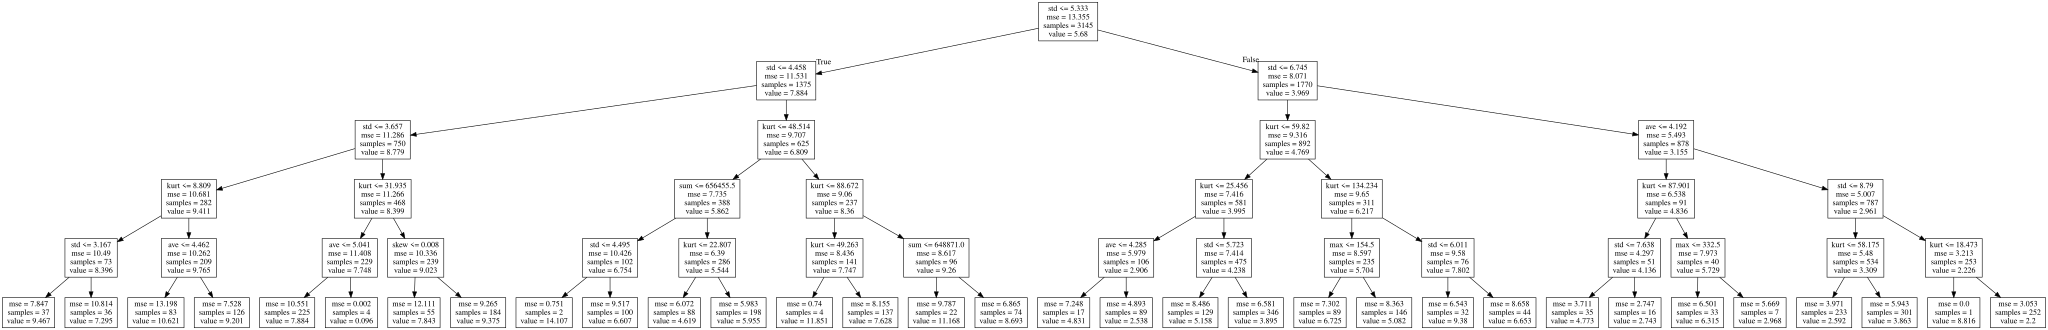

In [156]:
graphviz.Source(tree_graph)

 <a id="443"></a> <br>
### 4-4-3 SHAP Values
SHAP (SHapley Additive exPlanations) is a unified approach to explain the output of any machine learning model. SHAP connects game theory with local explanations, uniting several previous methods [1-7] and representing the only possible consistent and locally accurate additive feature attribution method based on expectations (see the SHAP NIPS paper for details).

In [157]:
row_to_show = 5
data_for_prediction = val_X.iloc[row_to_show]  # use 1 row of data here. Could use multiple rows if desired
data_for_prediction_array = data_for_prediction.values.reshape(1, -1)


tree_model.predict(data_for_prediction_array);

In [158]:
# Create object that can calculate shap values
explainer = shap.TreeExplainer(tree_model)

# Calculate Shap values
shap_values = explainer.shap_values(data_for_prediction)

>**Note**: Shap can answer to this qeustion : how the model works for an individual prediction?

In [ ]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values, data_for_prediction)

### 4-4-4 pdpbox

In [ ]:
from matplotlib import pyplot as plt
from pdpbox import pdp, get_dataset, info_plots

# Create the data that we will plot
pdp_goals = pdp.pdp_isolate(model=tree_model, dataset=val_X, model_features=X.columns, feature='std')

# plot it
pdp.pdp_plot(pdp_goals, 'std')
plt.show()

In [ ]:
# Create the data that we will plot
pdp_goals = pdp.pdp_isolate(model=rfc_model, dataset=val_X, model_features=X.columns, feature='kurt')

# plot it
pdp.pdp_plot(pdp_goals, 'kurt')
plt.show()

<a id="5"></a> <br>
# 5- Model Development

<a id="51"></a> <br>
# 5-1 SVM

In [ ]:
svm = NuSVR()
svm.fit(X_train_scaled, y_train.values.flatten())
y_pred_svm = svm.predict(X_train_scaled)

In [ ]:
score = mean_absolute_error(y_train.values.flatten(), y_pred_svm)
print(f'Score: {score:0.3f}')

<a id="52"></a> <br>
# 5-2 LGBM

 Defing folds for cross-validation

In [ ]:
folds = KFold(n_splits=5, shuffle=True, random_state=42)

LGBM params

In [ ]:
params = {'objective' : "regression", 
               'boosting':"gbdt",
               'metric':"mae",
               'boost_from_average':"false",
               'num_threads':8,
               'learning_rate' : 0.001,
               'num_leaves' : 52,
               'max_depth':-1,
               'tree_learner' : "serial",
               'feature_fraction' : 0.85,
               'bagging_freq' : 1,
               'bagging_fraction' : 0.85,
               'min_data_in_leaf' : 10,
               'min_sum_hessian_in_leaf' : 10.0,
               'verbosity' : -1}

In [ ]:
%%time
y_pred_lgb = np.zeros(len(X_test_scaled))
for fold_n, (train_index, valid_index) in tqdm(enumerate(folds.split(X))):
    print('Fold', fold_n, 'started at', time.ctime())
    X_train, X_valid = X.iloc[train_index], X.iloc[valid_index]
    y_train, y_valid = y.iloc[train_index], y.iloc[valid_index]
        
    model = lgb.LGBMRegressor(**params, n_estimators = 22000, n_jobs = -1)
    model.fit(X_train, y_train, 
                    eval_set=[(X_train, y_train), (X_valid, y_valid)], eval_metric='mae',
                    verbose=1000, early_stopping_rounds=200)
            
    y_pred_valid = model.predict(X_valid)
    y_pred_lgb += model.predict(X_test_scaled, num_iteration=model.best_iteration_) / folds.n_splits

<a id="53"></a> <br>
# 5-3 Catboost 

In [ ]:
train_pool = Pool(X,y)
cat_model = CatBoostRegressor(
                               iterations=3000,# change 25 to 3000 to get best performance 
                               learning_rate=0.03,
                               eval_metric='MAE',
                              )
cat_model.fit(X,y,silent=True)
y_pred_cat = cat_model.predict(X_test)

<a id="6"></a> <br>
# 6- submission

### submission for svm

In [ ]:
y_pred_svm= svm.predict(X_test_scaled)

In [ ]:
submission['time_to_failure'] = y_pred_cat
submission.to_csv('submission_svm.csv')

### Submission for LGBM

In [ ]:
submission['time_to_failure'] = y_pred_lgb
submission.to_csv('submission_lgb.csv')

### Submission for Catboost

In [ ]:
submission['time_to_failure'] = y_pred_cat
submission.to_csv('submission_cat.csv')

### Submission for Randomforest

In [ ]:
y_pred_rf=rfc_model.predict(X_test_scaled)

In [ ]:

submission['time_to_failure'] = y_pred_rf
submission.to_csv('submission_rf.csv')

<a id="61"></a> <br>
# 6-1 Blending

In [ ]:
blending = y_pred_svm*0.5 + y_pred_lgb*0.5 
submission['time_to_failure']=blending
submission.to_csv('submission_lgb_svm.csv')

In [ ]:
blending = y_pred_svm*0.5 + y_pred_cat*0.5 
submission['time_to_failure']=blending
submission.to_csv('submission_cat_svm.csv')